In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from functools import partial
from scipy.integrate import quad
import warnings
warnings.filterwarnings('ignore')

#plotting parametere
newparams = {'figure.figsize': (8.0, 4.0), 'axes.grid': True,
'lines.markersize': 8, 'lines.linewidth': 2,
'font.size': 8}
plt.rcParams.update(newparams)


## Oppgave 1 

#### Oppgave 1a)

Vi finner den tidsderiverte (venstre side)

$$
\frac{\partial \phi}{\partial t} = \frac{\partial}{\partial t} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right]
$$

og får 

$$
\frac{\partial \phi}{\partial t} = \int_{-\infty}^{\infty} dy \, h(y) \left( -\frac{1}{2t} + \frac{(x-y)^2}{4Dt^2} \right) \frac{1}{\sqrt{4\pi D t}} e^{-\frac{(x-y)^2}{4Dt}}.
$$

Vi regner første romderiverte (høyre side)

$$
\frac{\partial}{\partial x} \left[ \frac{1}{\sqrt{4\pi D t}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x-y)^2}{4Dt}} \right] =
 -\frac{1}{2Dt} \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) (x - y) e^{-\frac{(x - y)^2}{4Dt}}.
$$

Vi regner andre romderiverte (høyre side)

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{1}{\sqrt{4\pi Dt}} \int_{-\infty}^{\infty} dy \, h(y) e^{-\frac{(x - y)^2}{4Dt}} \left(- \frac{1}{2t} + \frac{(x - y)^2}{4D t^2} \right).
$$

multipliserer begge sider med D gjenkjenner vi resten av utrykket som det samme utrykket som for tidsderiverte

$$
D \frac{\partial^2 \phi}{\partial x^2} = \frac{\partial \phi}{\partial t}.
$$

Med dette, oppfyller $ \phi(x,t) $ varmelikningen

Med $\sigma = \sqrt{2Dt}$, får vi
$$
\phi(x, \sigma) =  \int_{-\infty}^{\infty} dy\, h(y) \frac{1}{\sqrt{2 \pi }\sqrt{\sigma}} e^{-\frac{1}{2}\frac{(x-y)^2}{\sigma ^2}},
$$

Dette er et integral av en gaussisk funksjon, skalert av funksjonen $h(y)$. 

Den gaussiske funksjonen beskriver hvordan bidrag fra et startpunkt y fordeler seg i rommet over tid ved diffusjon. For hvert startpunkt y, beksriver den Gausisske faktoren sannsynsligheten for at den partikkelen som startet i y, befinner seg i x etter tiden t. Løsningen $ \phi(x,t) $ fås ved å summere bidragene fra alle startpunkter, vektet med den opprinnelige fordelingen $ h(y) $

Når $ t \to 0 $, går $\sigma \to 0$, blir den Gaussiske funksjonen ekstremt smal rundt y=x, samtidig som arealet under kruven forblir lik 1. I denne grensen oppfører den Gaussiske funksjonen seg som en dirac-delta funksjon med parameter $y-x$.

$$
\lim_{t \to 0} \phi(x,t) = \int_{-\infty}^{\infty} dy \, h(y) \delta(y - x),
$$

Som kan forenkles til

$$
\phi(x,0) = h(x).
$$

Dette betyr at $ h(y) $ representerer den initielle fordelingen av partikler langs x-aksen ved t=0. 

##### Oppgave 1b)


Vi har relasjonene:
$$
p^+ \propto P(x_0 + 1), \quad p^- \propto P(x_0 - 1), \quad p^0 \propto P(x_0),
$$
Sammen med definisjonen av sannsynlighet gir:
$$
p^+ = \frac{P(x_0 + 1)}{P(x_0) + P(x_0 + 1) + P(x_0 - 1)},
$$
samme vil være sant for $ p^- $ og $ p^0 $. Ved å substutiere inn $ P(x) = e^{-\beta V(x)} / Z $, gir oss
$$
p^+ = \frac{e^{-\beta V(x_0 + 1)}}{e^{-\beta V(x_0)} + e^{-\beta V(x_0 + 1)} + e^{-\beta V(x_0 - 1)}}
$$
Som videre forenkles til
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}
$$

Samme for $ p^- $ og $ p^0 $, gir oss
$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}}
$$
og
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}
$$

#### Oppgave 1c)

I høytemperaturgrensen $k_B T \gg |V(x+1) - V(x)|$ , vil de eksponensielle leddene nærme seg 1. Dermed blir overgangssansynlighetene $p^+$, $p^0$, og $p^-$ all tilnærmet like og nær $1/3$. Når temperaturen er høy, har partiklene mye termisk energi. Denne energien er mye større enn forskjellen i potensialet mellom nabopunktene. Det betyr at partiklene nesten ikke "merker" potensialet. Som følge av dette blir sannsynlighetene for å gå fremover, bakover eller bli stående omtrent like store. Partiklene beveger seg derfor tilfelif  uten noen foretrukken retning. Bevegelsen kan da beskrives som en symmetrisk og isotrop tilfeldig vandring. 


I lavtemperaturgrensen $k_B T \ll |V(x+1) - V(x)|$, blir $\beta$ stor, slik at selv små forskjeller i potensialet får stor betydning. Dette fører til at enten $p^+$ or $p^-$ går mot 1, mens de øvringe overgangssannsynlighetene går mot 0. Når temperaturen er lav, har partiklene lite termisk energi. Da får selv små forskjeller i potensialet stor betydning for hvordan partiklene beveger seg. I dette tilfellet vil partiklene nesten alltid bevege seg i retning av lavere potensial. Overgangssanssynligheten i denne retningen blir nær 1, mens de andre blir nærmere 0. Bevegelsen blir derfor ikke lenger tilfelidg, men styrt av potensialet. 


I høytemperaturtilfellet kan potensialet derfor neglisjerer sammenlignet med de termiske fluktuasjonene, og systemet kan modelleres som en symmetrisk tilfeldig vandring. I lavtemperaturtilfellet vil partiklene derimot systematisk bevege seg mot lavere potensial, noe som innebærer at partiklene etter hvert vil konsentrere seg i områdene nær potensialminimum. 

## Oppgave 2

##### Oppgave 2a)


In [18]:

Np = 101 #antall partikler, må være oddetall for dte skal være en partikkel i midten
Tp = 200 #antall iterasjoner
runs = 100 #antall ganger vi kjører simWalk
h = 1 #skrittlengde
dt = 1 #tidssteg
k = 1.0 #styrken på potensialet
B = 1.0 #invers temperatur


np.random.seed(7)

def V_const(x, k):
    return k * np.ones_like(x, dtype=float) #for V(x)=k, lager et array med bare k

def V_linear(x, k): #for V(x)=-k*x
    return -k * x

def pPlus(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos-1, k) - Vfunc(pos+1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos+1, k))))

def pMin(Vfunc, B, pos, k):
    return 1.0 / (1.0+ np.exp(-B*(Vfunc(pos+1, k) - Vfunc(pos-1, k)))+ np.exp(-B*(Vfunc(pos,   k) - Vfunc(pos-1, k))))

def simStep(Vfunc, B, pos, h, k):
    p_plus = pPlus(Vfunc, B, pos, k) #pPlus gir sannsynligheten for å gå til høyre, og pMin for å gå til venstre
    p_min  = pMin(Vfunc, B, pos, k)

    r = np.random.uniform(size=pos.size) #genererer et array med tilfeldige tall mellom 0 og 1, som skal brukes til å bestemme om vi går til høyre eller venstre

    pos = pos.copy() #lager en kopi av pos, slik at vi ikke endrer på originalen mens vi irerer gjennom den. Pos er et array som representerer posisjonen til hver partikkel, og vi skal oppdatere denne basert på sannsynligheten for at hver partikkkel er der.
    pos[r <= p_min] -= h #hvis det tilfeldige taller er mindre eller lik p_min, så går vi til venstre, og pos oppdatered ved å trekke h fra den. 
    pos[r > 1 - p_plus] += h
    return pos

def simWalk(Vfunc, B, pos0, Tp, dt, h, k): #simulerer en random walk for alle partikler i pos0, og retirnerer den endelige posisjonen etter Tp iterasjoner
    pos = pos0.copy()
    for _ in range(int(Tp/dt)): 
        pos = simStep(Vfunc, B, pos, h, k) 
    return pos

def run_case(Vfunc, B, V_label, pos0_mode="spread", a=False, xlim=None): #kjører simWalk flere ganger, og plotter histogram av den endelige posisjonen til alle partikler etter Tp iterasjoner. 
    if pos0_mode == "spread":
        pos0 = np.arange(Np) - Np//2
    else:
        pos0 = np.zeros(Np, dtype=int)

    all_final = [] #lager en tom liste som skal fylles med den endelige posisjonen til alle partikler etter Tp iterasjoner.
    for _ in range(runs):
        all_final.append(simWalk(Vfunc, B, pos0, Tp, dt, h, k))
    all_final = np.concatenate(all_final)

    print("pos0 min/max:", pos0.min(), pos0.max())
    print("final min/max:", all_final.min(), all_final.max(), "mean:", all_final.mean())

    if a==True: #hvis jeg skal ha normalfordeling på hsitogrammet
        mu = np.mean(all_final) #beregner gjennomsnittet av den 
        sigma = np.std(all_final)

        x = np.linspace(all_final.min(), all_final.max(), 400)
        pdf = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2)





    plt.figure()
    plt.hist(all_final, bins=150, density=True, alpha=0.6,
             color="deeppink", label=rf'$\beta k={B*k:.2f}$')
    if a==True:
        plt.plot(x, pdf, color="blue", linewidth=3, label=rf'Fitted normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)')
    plt.title(rf"Random walk når {V_label}")
    plt.xlabel(rf"Position after {Tp} iterations, $x$")
    plt.ylabel("Density")
    plt.xlim(xlim)
    plt.legend()
    plt.grid(True)
    plt.show()





#### Tilfelle (i)

pos0 min/max: -50 50
final min/max: -87 91 mean: 0.04712871287128713


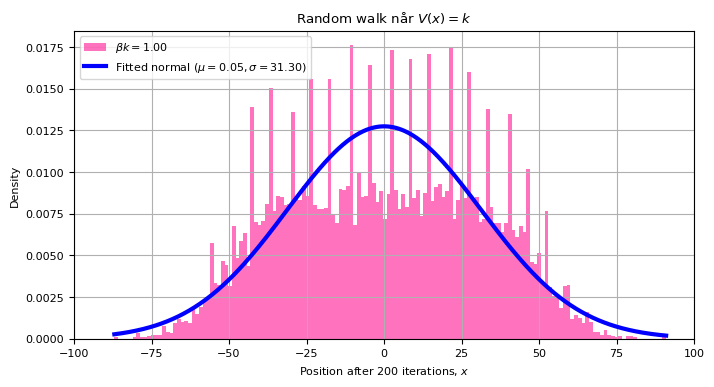

In [19]:
run_case(V_const, B, r"$V(x)=k$", pos0_mode="spread", a=True, xlim=(-100, 100))


#### Tilfelle (ii)

pos0 min/max: -50 50
final min/max: 37 188 mean: 114.90029702970297


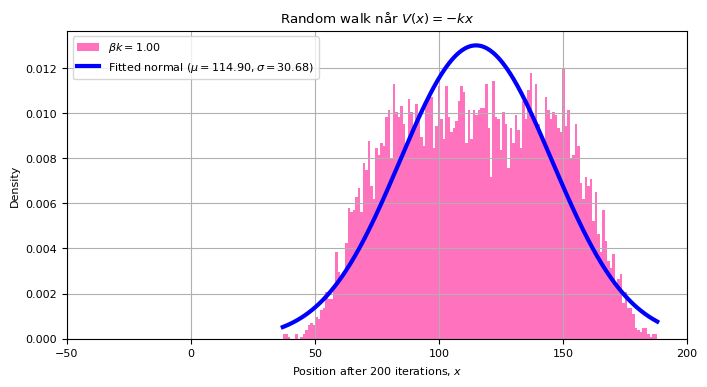

In [66]:
run_case(V_linear, B, r"$V(x)=-kx$", pos0_mode="spread", a=True, xlim=(-50, 200))

#### Diskusjon

For $V(x)=k$ (konstant potensial) ser vi at fordelingen er symmetrisk og tilnærmet normalfordelt rundt $\mu \approx 0$, med $\sigma \approx 31.29$. Dette er i tråd med teorien: når potensialet er konstant, er sannsynlighetene for å gå til høyre og venstre like store ($p^+ = p^- = 1/3$), og prosessen blir en symmetrisk random walk med en ikke-null sannsynlighet for å stå stille. Ifølge sentralgrenseteoremet vil summen av mange uavhengige steg nærme seg en normalfordeling, og variansen vokser lineært med antall tidssteg $T$.

Hvis alle partikler hadde startet i $x=0$, ville vi forventet diffusiv spredning gitt av variansen per steg. For et flatt potensial har vi

$$
p^+ = p^- = p^0 = \frac{1}{3}.
$$

Dette gir

$$
\mathrm{Var}(\Delta x) = \frac{2}{3}.
$$

Med $T=200$ får vi derfor en forventet diffusiv spredning

$$
\sigma_{\text{diff}} = \sqrt{\frac{2T}{3}} 
= \sqrt{\frac{400}{3}} 
\approx 11.5.
$$

I denne simuleringen starter partiklene ikke i $x=0$, men er allerede fordelt over intervallet $[-50,50]$. Den observerte spredningen i sluttfordelingen blir derfor en kombinasjon av startspredning og diffusjon,

$$
\sigma_{\text{total}}^2 \approx \sigma_{\text{start}}^2 + \sigma_{\text{diff}}^2,
$$

som forklarer hvorfor vi får en betydelig større verdi $\sigma \approx 31$ enn $\sigma \approx 11.5$.

For $V(x)=-kx$ ser vi at fordelingen er forskjøvet mot positive $x$-verdier, med $\mu \approx 114.9$. Dette kan forklares ved å beregne forventet drift per steg. Siden
$$
V(x_0+1)-V(x_0)=-k,\qquad V(x_0-1)-V(x_0)=+k,
$$
følger det fra ligning (8) at sannsynligheten for et steg mot høyre er større enn for et steg mot venstre ($p^+ > p^-$). 
$$
p^+ = \frac{1}{1 + e^{-\beta [V(x_0 - 1) - V(x_0 + 1)]} + e^{-\beta [V(x_0) - V(x_0 + 1)]}}
$$

$$
p^- = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0 - 1)]} + e^{-\beta [V(x_0) - V(x_0 - 1)]}}
$$
$$
p^0 = \frac{1}{1 + e^{-\beta [V(x_0 + 1) - V(x_0)]} + e^{-\beta [V(x_0 - 1) - V(x_0)]}}
$$


Med $\beta k=1$, gir numerisk verdi $p^+ \approx 0.665$ og $p^- \approx 0.090$, slik at forventet steg blir
$$
\mathbb{E}[\Delta x]=p^+-p^- \approx 0.575.
$$
Etter $T=200$ steg forventer vi derfor
$$
\mathbb{E}[x_T]\approx T\,\mathbb{E}[\Delta x]\approx 200\cdot 0.575 \approx 115,
$$
som stemmer godt med simuleringen. 

Til forskjell fra $V(x)=k$, der $p^+=p^- $ og vi får $\mu \approx 0$ uten drift, gir $V(x)=-kx$ en systematisk drift i tillegg til diffusjon grunnet avtagende potensial. Spredningen $\sigma$ er fortsatt stor fordi starttilstanden er utbredt over $[-50,50]$.


#### Oppgave 2b)

In [ ]:
def simStep_hardcore(Vfunc, B, pos, h, k):
    #Ett tidssteg der alle partikler prøver å flytte én gang i tilfeldig rekkefølge, med hard core exclusion.
    
    Np_local = pos.size
    order = np.random.permutation(Np_local)

    occupied = set(pos.tolist())
    pos=pos.copy()

    for i in order:
        x0 = pos[i]
        p_plus = pPlus(Vfunc, B, x0, k)
        p_min  = pMin( Vfunc, B, x0, k)

        r = np.random.rand()

        if r <= p_min:
            x_new = x0 - h
        elif r > (1 - p_plus):
            x_new = x0 + h
        else:
            continue  

        if x_new in occupied:
            continue

        occupied.remove(x0)
        occupied.add(x_new)
        pos[i] = x_new

    return pos

def simWalk_hardcore(Vfunc, B, pos0, Tp, dt, h, k):
    pos = pos0.copy()
    for _ in range(int(Tp/dt)):
        pos = simStep_hardcore(Vfunc, B, pos, h, k)
    return pos

In [ ]:
def run_case_hardcore(Vfunc, B, V_label, pos0_mode="spread", a=False, xlim=None):
    if pos0_mode == "spread":
        pos0 = np.arange(Np) - Np//2
    else:
        pos0 = np.zeros(Np, dtype=int)

    all_final = []
    for _ in range(runs):
        all_final.append(simWalk_hardcore(Vfunc, B, pos0, Tp, dt, h, k))
    all_final = np.concatenate(all_final)

    print("pos0 min/max:", pos0.min(), pos0.max())
    print("final min/max:", all_final.min(), all_final.max(), "mean:", all_final.mean())


    if a==True: #hvis jeg skal ha normalfordeling på hsitogrammet
        mu = np.mean(all_final) #beregner gjennomsnittet av den 
        sigma = np.std(all_final)

        x = np.linspace(all_final.min(), all_final.max(), 400)
        pdf = (1/(sigma*np.sqrt(2*np.pi))) * np.exp(-0.5*((x-mu)/sigma)**2)





    plt.figure()
    plt.hist(all_final, bins=110, density=True, alpha=0.6,
             color="violet", label=rf'$\beta k={B*k:.2f}$')
    if a==True:
        plt.plot(x, pdf, color="Blue", linewidth=3, label=rf'Fitted normal ($\mu={mu:.2f}, \sigma={sigma:.2f}$)')
    plt.title(rf"Hardcore når {V_label}")
    plt.xlabel(rf"Position after {Tp} iterations, $x$")
    plt.ylabel("Density")
    plt.xlim(xlim)
    plt.legend()
    plt.grid(True)
    plt.show()


#### Tilfelle (i)

pos0 min/max: -50 50
final min/max: -85 84 mean: -0.0031683168316831685


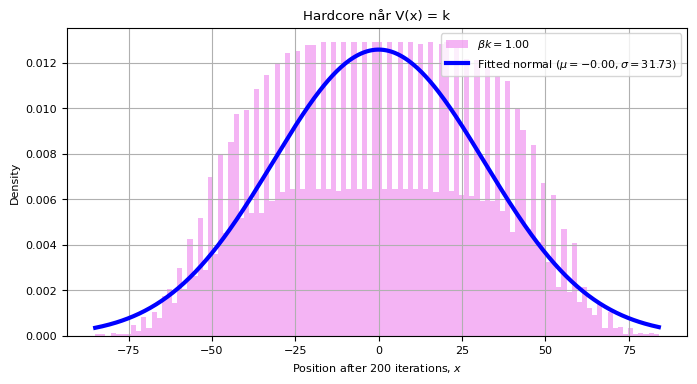

In [79]:
run_case_hardcore(V_const, B, "V(x) = k", pos0_mode="spread", a=True)

#### Tilfelle (ii)

pos0 min/max: -50 50
final min/max: -46 195 mean: 41.965643564356434


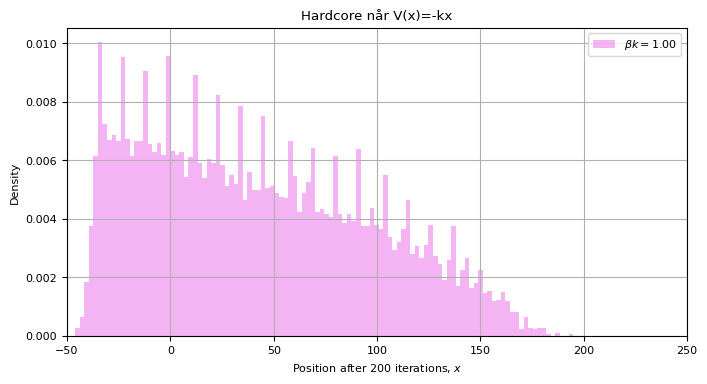

In [31]:
run_case_hardcore(V_linear, B, "V(x)=-kx", pos0_mode="spread", a=False, xlim=(-50, 250))

#### Diskusjon

For $V(x)=k$ (konstant potensial) er energien den samme på alle posisjoner. Fra ligning (8) følger det at $p^+=p^-=p^0=1/3$. Random walken er dermed fortsatt symmetrisk. Forventningsverdien er fortsatt tilnærmet 0 med $\mu \approx -0.02$. Den målte spredningen er $\sigma \approx 31.73 $, tilnærmet det vi så i oppgave 2a (i). Årsaken er at, selv om partiklene ikke kan overlappe, vil de i et flatt potensial i gjennomsnitt forsøke å bevege seg like mye i begge retninger. Hard core-interasksjonen påvirker derfor i liten grad fordeligstypen. Spredningen på rundt 31 forklares på samme måte som i 2a. 

For $V(x)=-kx$, avtar potensialet med økende x, helt likt som i 2a (ii). Overgangssansynligheten med bevegelse mot høyre blir igjen favorisert av samme grunn. Partiklene starter jevnt mellom $[50, 50]$. Sluttresultatet viser at det er en tydlig driv mot høyre, hvorav de havner mellom $-46$ og $195$ og forventningsverdien ligger på $41.97>>0$. En forventningsverdi på $41.97$ er likevel betydlig mindre enn det vi så i 2a (ii), hvor den lå på 115. Fordelingen er også ikke lenger tilnærmet gaussiks, men blir i stedet skjev med høy tetthet mot venstre side og en lang hale mot høyre. Dette kan forklares ved at partiklene starter tett pakket mellom $[-50, 50]$. Partiklene lengst til høyre kan bevege seg relativt fritt i retning av lavere potensial, mens partikler lenger bak ofte hindres av andre partikler foran seg. 

Sammenlignet med oppgave 2a ser vi at hard core-interaksjonen har liten effekt i et flatt potensial som $V(x)=k$, fordi random walken er fortsatt symmetrisk og blokkeringer skjer omtrent like ofte i begge retninger. For det lineære potensialet $V(x)=-kx$ får interaksjonene derimot stor effekt.




#### Oppgave 2c)

pos0 min/max: -50 50
final min/max: -86 80 mean: 0.05841584158415842


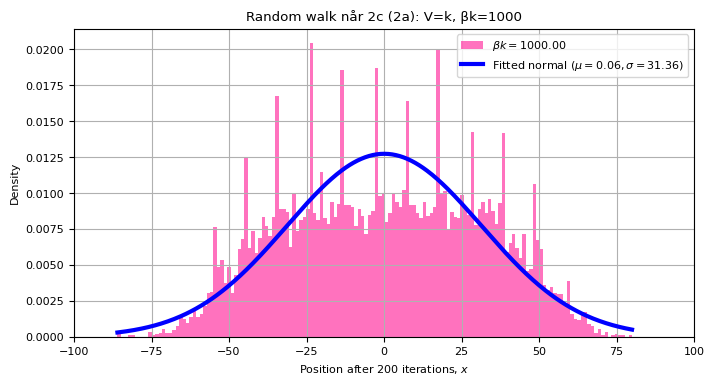

In [68]:
run_case(V_const, 1000, "2c (2a): V=k, βk=1000", pos0_mode="spread", a=True, xlim=(-100, 100))


pos0 min/max: -50 50
final min/max: 150 250 mean: 200.0


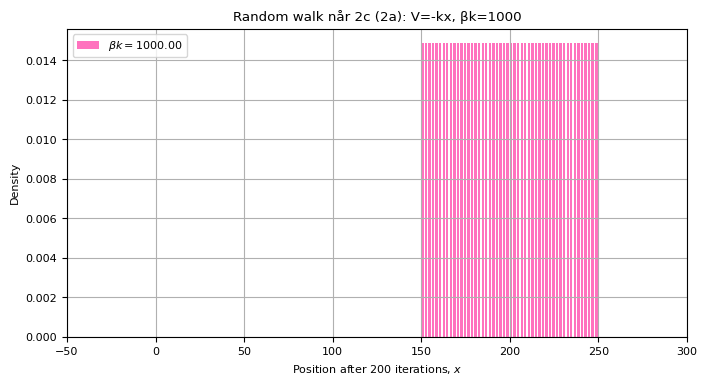

In [81]:
run_case(V_linear, 1000, "2c (2a): V=-kx, βk=1000", pos0_mode="spread", xlim=(-50, 300))


pos0 min/max: -50 50
final min/max: -85 81 mean: 0.02297029702970297


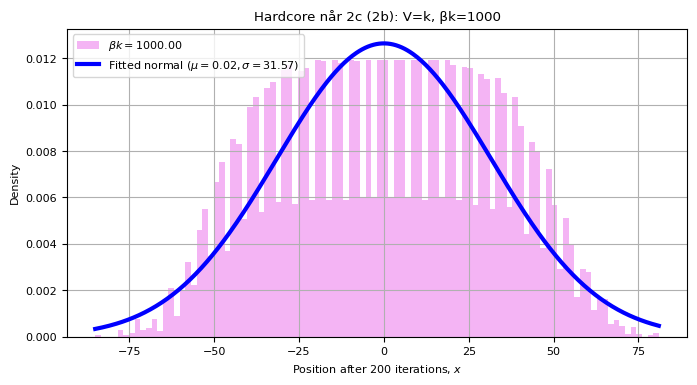

In [11]:

run_case_hardcore(V_const, 1000, "2c (2b): V=k, βk=1000", pos0_mode="spread", a=True)


pos0 min/max: -50 50
final min/max: 50 250 mean: 150.0239603960396


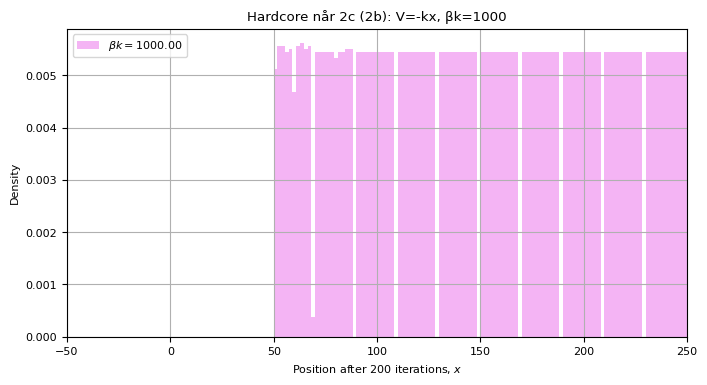

In [34]:
run_case_hardcore(V_linear, 1000, "2c (2b): V=-kx, βk=1000", pos0_mode="spread", a=False, xlim=(-50, 250))

### Diskusjon 

Forskjellen fra 2a, 2b og til de respektive plottene i 2c, er temperaturen. $\beta k=1000$ når $k=1$, betyr $\beta =1000$, som igjen gir $\beta =1/(k_B T) $. Det betyr veldig lav temperatur.

For både 2a (i) og 2b (ii), vil man ikke se noen endirng. Potensialet er konstant, vi får fortsatt like store overgangssanysynlighetene $p^+=p^-=p^0=1/3 $. Det er helt uanvhengig temperaturen. Det kommer fra utrykket av overgangssansynlighetene i likning 8.


Siden alle potensialene er konstante, følger

$$
V(x_0-1)-V(x_0+1)=0, \qquad V(x_0)-V(x_0+1)=0.
$$

Dermed får vi

$$
p^+ =
p^- =
p^0 =
\frac{1}{1 + e^{0} + e^{0}}
=
\frac{1}{3}.
$$


Random walken er fortsatt symmetrisk. Det er ingen drift, og samme diffusjon. 

&emsp; 

For $V(x)=-kx$ ser vi en markant forskjell når temperaturen senkes til $\beta k = 1000$, sammenlignet med tilfellet $\beta k = 1$ gitt i 2a (ii). 

Ved $\beta k=1$ får man både drift og diffusjon. Fordelingen i 2a (ii) er forskjøvet mot høyre og har betydelig bredde med $\mu \approx 114.9$ og $\sigma \approx 30.7$. Når $\beta k = 1000$ blir partiklene veldig forskjøvet uten særlig bredde, fordi overgangssansynlighetene peker kun én vei. Fra ligning 8 får man:
$$
V(x_0-1)-V(x_0+1)=2k,\qquad V(x_0)-V(x_0+1)=k,
$$
slik at
$$
p^+ = \frac{1}{1+e^{-2\beta k}+e^{-\beta k}} \approx 1,
$$
mens
$$
p^- = \frac{1}{1+e^{2\beta k}+e^{\beta k}} \approx 0,
\qquad
p^0 = \frac{1}{1+e^{\beta k}+e^{-\beta k}} \approx 0.
$$
Dermed beveger nesten alle partikler seg mot høyre ved nesten hvert tidssteg.

Dette stemmer med plottet.  Sluttposisjonene ligger i intervallet $[150,250]$ med gjennomsnitt $\mu \approx 200$. Dette samsvarer med at startintervallet er $[-50,50]$ og at hver partikkel flyttes omtrent $+200$ etter $T=200$ steg, altså
$$
x_T \approx x_0 + 200,
$$
som gir sluttintervall $[-50+200,\, 50+200]=[150,250]$ og middelverdi $\mu \approx 200$. Ved så lav temperatur dominerer driften fullstendig og diffusjonen blir sterkt undertrykt.


&emsp; 

Man ser på samme måte en tydlig forskjell for $V(x)=-kx$ med hard core-repusion fra 2b (ii), når temperaturen senkes fra $\beta k = 1$ til $\beta k = 1000$. 

Når $\beta k = 1$, får man fortsatt en tydelig drift mot høyre. Histogrammet er forskjøvet mot positive $x$-verdier, og gjennomsnittet blir $\mu \approx 41.97$. Samtidig er fordelingen relativt bred fordi partiklene kan bevege seg både mot høyre og venstre, selv om steg mot høyre er mer sannsynlige, hvorav $p^+ \approx 0.665$ og $p^- \approx 0.09 $.

Når temperaturen derimot senkes til $\beta k = 1000$, blir overgangssansynlighetene $p^-$ neglisjerbar. 
For det lineære potensialet
$$
V(x)=-kx
$$
får man energiforskjellene
$$
V(x_0+1)-V(x_0)=-k, \qquad V(x_0-1)-V(x_0)=+k.
$$
Setter man dette inn i ligning (8), får man
$$
p^+ = \frac{1}{1+e^{-\beta[V(x_0-1)-V(x_0+1)]}+e^{-\beta[V(x_0)-V(x_0+1)]}}
$$

$$
= \frac{1}{1+e^{-\beta(2k)}+e^{-\beta(k)}}.
$$

Når $\beta k =1000$ blir

$$
e^{-\beta k}=e^{-1000} \approx 0,
\qquad
e^{-2\beta k}=e^{-2000} \approx 0.
$$

Dermed får man

$$
p^+ \approx \frac{1}{1+0+0}=1.
$$

Tilsvarende får man

$$
p^-=\frac{1}{1+e^{\beta(2k)}+e^{\beta(k)}}.
$$

Når $\beta k=1000$ blir

$$
e^{\beta k}=e^{1000}\gg 1,
$$

slik at

$$
p^- \approx 0.
$$

Dermed får vi

$$
\mathbb{E}[\Delta x]=p^+-p^- \approx 1.
$$

Partiklene flytter seg altså i teorien ett steg mot høyre i hvert tidssteg. Man ville derfor tenkt at det siste plottet skulle ligne plottet fra 2a (ii) med $\beta k = 1000$, ettersom begge har $p^+ \approx 1$. Vi ser derimot at plottet fra 2b (ii) med $\beta k = 1000$, har en "spredning" mellom 50 og 250, i stedet for 150 og 250. Dette skyldes hard core-repusjon hvoav at partikler ikke kan passere hverandre. Når alle partikler forsøker å bevege seg mot høyre, kan noen bli blokkert av partikler foran seg og dermed bli stående stille i enkelte tidssteg. 

$$
x_T = x_0 + N_{\text{acc}},
$$

der $N_{\text{acc}}$ er antall aksepterte steg. På grunn av blokkeringene varierer dette tallet omtrent mellom $100$ og $200$, noe som gir sluttposisjoner i intervallet

$$
x_T \in [50,250],
$$

som samsvarer med det vi ser i plottet. 




Et spørsmål man kan sitte igjen med her er muligens hvorfor man ikke får noen feil når man i definisjonen sier at den totale sannsynligheten er noe over 1. I og med at $p^+=1$, eksakt fra definisjonen, og $p^- $ blir noe i en stærrelsesorden av $\exp(-1000)$, som riktig nok er veldig nært 0, men ikke helt. Man skulle kanskje tenkt at det ville rotet til matematikken, men numeriske metoder er vel ikke presise nok til å plukke opp på det. 









### Oppgave 3

In [37]:



def build_V1(alpha, N_x):
    peak = int(alpha * N_x)
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - n[right]) / max((N_x - peak), 1)
    
    return np.concatenate([V, V])




def simulate_ratchet(alpha, T_p=500, N_x=100, Beta_k=1000, n_cycles=10,frø=0, plot=False, N_p=None, x_init=None, a=False):
    P=2*N_x

    if N_p is None:
        N_p = 12 * N_x
    n_steps=2*T_p*n_cycles
    
    np.random.seed(frø)  

    V1 = build_V1(alpha, N_x)
    V2 = np.zeros(P)


    #initaltilstand
    if x_init is None:
        x = np.repeat(np.arange(P), N_p//P) #jevnt fordelt, 6 per punkt
    else:
        x=x_init.copy() 

    J = np.zeros(n_steps)

    for i in range(n_steps):

        if ((i // T_p) % 2 == 0):
            V = V2
        else:
            V = V1
        
        V_l = V[(x - 1) % P]
        V_0 = V[x]
        V_r = V[(x + 1) % P]

        p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
        p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))

        r = np.random.rand(len(x))
    
        pos = np.zeros_like(x) # tomt array med posisjon 0
        pos[r < p_minus] = -1
        pos[r > 1 - p_plus] = +1

        n_plus  = np.sum(pos == 1) # teller hvor mange partikelr som gikk til høyre
        n_minus = np.sum(pos == -1) # teller hvor mange partikelr som gikk til venstre
        J[i] = (n_plus - n_minus) / N_p  # current J[i]

        x = (x + pos) % P  # randbet, x0 -> x199

  
    J_avg = np.zeros(n_cycles)
    cycle_length = 2 * T_p
    for n in range(n_cycles):
        start = n * cycle_length
        end = (n + 1) * cycle_length
        J_avg[n] = np.mean(J[start:end])
        if a==True:
            print(n , J_avg[n])

    if plot==True:
        plt.plot(np.arange(N_x), V1[:N_x])
        plt.xlabel("x")
        plt.ylabel("$V_1(x)$")
        plt.title(r"Sagtannpotensial med $\alpha$ ="+str(alpha))
        plt.grid(True)
        plt.show()    

    return J_avg, J, V1

    #Plot to sagtanner (hele systemet, lengde P = 2*N_x)




#### Oppgave 3a)

0 -0.031083333333333334
1 -0.012833333333333334
2 -0.01425
3 -0.014166666666666666
4 -0.01375
5 -0.012833333333333332
6 -0.01375
7 -0.013083333333333334
8 -0.014166666666666668
9 -0.01425


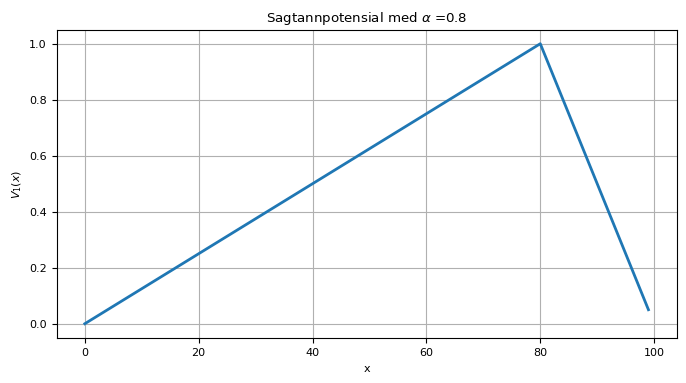

In [33]:
J_avg, J, V1 = simulate_ratchet(0.8, plot=True, a=True)

#### Diskusjon

##### For $\alpha$ = 0.8
Avhengig av hvilken "seed" som brukes vil koden skrive ut ulike verdier for de 10 ulike syklusene. For å få reproduserbare resultater ble seed i denne koden satt til 0, og resultatene ble som følger;


| Cycle    | $J_{avg}$ for $\alpha$ = 0.8|         
|:---------|:---------------------------:|
|     1    |  -0.03108 | 
|     2    | -0.01283   | 
|     3    |  -0.01425   | 
|     4    |  -0.01417   | 
| 5        |  -0.01375   |  
|  6       |  -0.01283   |  
|  7       |  -0.01375   |  
|  8       |  -0.01308   | 
|  9       |  -0.01417   |
|  10       |  -0.01425  |

Siden $\alpha$ > 0.5 betyr det at toppen av sagtannen er forskjøvet mot høyre. Som obervert i tabellen og fra utskriften av koden er all strømningen $J_{avg}$ negativ. I første periode $T_p$ er potensialet helt flatt og partiklene sprer seg tilfeldig. Etter endt periode skrur sagtannpotenialet seg på. Hvordan dette sagtannpotensialet vil se ut er fremstilt i plottet ovenfor. Det viser en topp i $\alpha$ = 0.8, en slak bakke som heller mot venstre og en bratt bakke som heller ned mot høyre. Når dette potensialet er påslått vil partiklener ønske å bevege seg "nedover", altså mot et lavere potensial. Ettersom $\alpha$ er forskjøvet mot høyre vil dermed flere partikler ende opp med å gli ned mot venstre. Det er dette som gir negativ strømning. Den fysiske betydningen av dette er at flere partikler i snitt vil gå ett steg mot venstre over tid.

Som observert i tabellen ovenfor er det en stor økning i $J_{avg}$ fra første til andre syklus.  

In [28]:
J0 = J_avg[0]
J1 = J_avg[1]

change = (J1 - J0) / np.abs(J0) * 100 # %
print(f"Endringen fra første til andre syklus er lik {change:.2f} %")

Endringen fra første til andre syklus er lik 58.71 %


Prosentvis er endringen fra syklus 1 til 2 tilnærmet lik 59.80% slik som regnet ut ovenfor, noe som er en markant økning. I starttilstanden til systemet er partiklene helt jevnt fordelt. Det vil dermed ikke være noen foretrukken retning og vil fysisk ikke ligne en naturlig tilstand. Etter første syklus vil partiklene ikke være jevnt fordelt og systemet får et "minne". Dermed kan partiklene falle mer effektiv og strømmen stabiliserer seg. Verdiene flukturer mellom verdiene -0.0137 og -0.0125, noe som kan indikere at systemet har nådd steady state, altså at den har "glemt" starttilstanden. 

0 0.040083333333333346
1 0.026750000000000003
2 0.030500000000000003
3 0.03141666666666667
4 0.029
5 0.028333333333333335
6 0.0265
7 0.02925
8 0.028666666666666667
9 0.028166666666666663


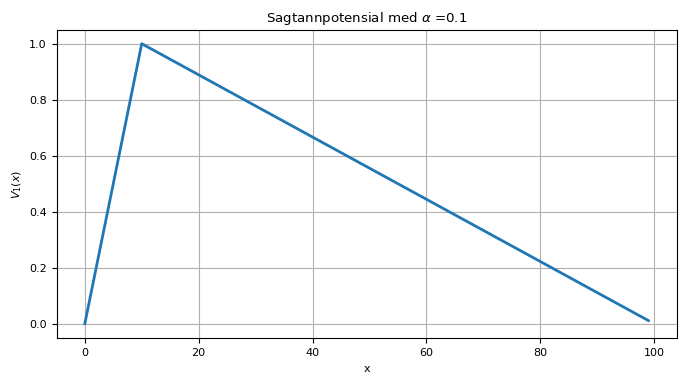

In [34]:
J_avg2, J2, V12 = simulate_ratchet(0.1, plot=True, a=True)


##### For $\alpha$ = 0.1

Ved å sette $\alpha$ = 0.1 blir toppen av sagtannpotensialet forskjøvet mot venstre slik som obersvert i plottet ovenfor. Dette vil dermed resultere i positive verdier for strømningen $J_{avg}$;

| Cycle    | $J_{avg}$ for $\alpha$ = 0.1|         
|:---------|:---------------------------:|
|     1    |  0.04008  | 
|     2    | 0.0280017   | 
|     3    |  0.0315083  | 
|     4    |  0.0323358   | 
| 5        |  0.0295708|  
|  6       |  0.0287525   |  
|  7       |  0.0273492   |  
|  8       |  0.0298233   | 
|  9       |  0.0297683   |
|  10       |  0.0286700  |

I likhet med når $\alpha$ = 0.8 oppleves en assymetrisk forskyvning som resulterer i at strømningen går i en spesifikk retning. For $\alpha$ = 0.1 gir det positiv strømning, altså går  $J_{avg}$ mot høyre. Ettersom toppen av sagtannen er forskjøvet enda mer i forhold til sentrum for $\alpha$ = 0.1 gir dette også høyere verdier når du ser på absoluttverdien til $J_{avg}$ kontra for $\alpha$ = 0.8. Igjen vil det være et flatt potensial i en tidsperiode $T_p$ før potensialet $V_1$ blir påslått og partiklene vil gli nedover mot lavest potensial. I fysisk betydning vil altså $J_{avg}$ i snitt gå mot høyre.

In [35]:
J0 = J_avg2[0]
J1 = J_avg2[1]

change = (J1 - J0) / np.abs(J0) * 100 # %
print(f"Endringen fra første til andre syklus i prosent er lik {change:.2f}")

Endringen fra første til andre syklus i prosent er lik -33.26


For $\alpha$ = 0.1 blir det en negativ prosentmessig endring fra første til andre syklus. Det tilsier alstå at strømmen endres i retning mot null. Etter å ha gått gjennom flere sykluser vil dette systemet i likhet med forrige stabilisere seg rundt en bestemt verdi. 

#### Oppgave 3b)

Utvalgte punkter:
T_p =    1,  J_avg =  0.000000
T_p =  103,  J_avg = -0.002913
T_p =  205,  J_avg = -0.008841
T_p =  307,  J_avg = -0.013151
T_p = 1001,  J_avg = -0.010839

Mest negativ (minimum):
T_p = 368,  J_avg = -0.013995

Første T_p der J_avg < -1e-3:
T_p = 103,  J_avg = -0.002913

Snitt av siste 5 punkter (store T_p): -0.011019


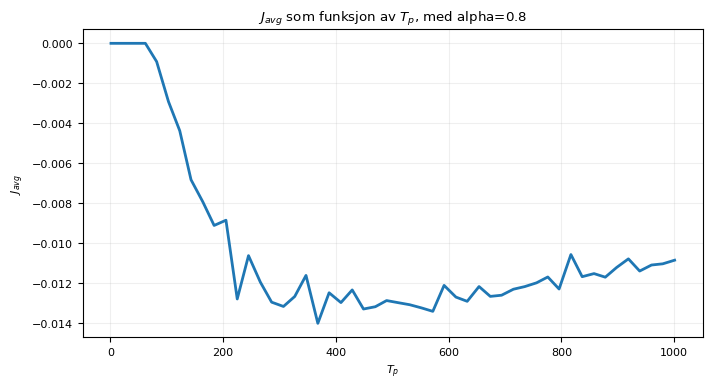

In [54]:

alpha=0.8
N_x=100
P = 2 * N_x
N_p = 40 * N_x

T_p_vals = np.linspace(1, 1001, 50).astype(int)

#finn minima i V1 (to sagtanner)
V1_tmp = build_V1(alpha, N_x)
min1 = np.argmin(V1_tmp[:N_x])
min2 = N_x + np.argmin(V1_tmp[N_x:])

#initialtilstand: halvparten i hvert minimum
x0 = np.array([min1] * (N_p // 2) + [min2] * (N_p // 2), dtype=int)

J_avg_vals = np.zeros(len(T_p_vals))

for i, T_p in enumerate(T_p_vals):
    J_avg, _, _ = simulate_ratchet(alpha=0.8, T_p=T_p,  N_x=100, N_p=40*N_x ,n_cycles=1, frø=i, x_init=x0, a=False, plot=False)
    J_avg_vals[i] = J_avg[0]

 # 1) noen faste punkter (start, litt tidlig, midt, slutt)
idx_list = [0, 5, 10, 15, -1]  # juster hvis du vil
print("Utvalgte punkter:")
for idx in idx_list:
    print(f"T_p = {T_p_vals[idx]:4d},  J_avg = {J_avg_vals[idx]: .6f}")

# 2) minimum (mest negativ strøm)
imin = np.argmin(J_avg_vals)
print("\nMest negativ (minimum):")
print(f"T_p = {T_p_vals[imin]},  J_avg = {J_avg_vals[imin]: .6f}")

# 3) når strømmen først blir 'tydelig' negativ (terskel)
threshold = -1e-3
neg_idx = np.where(J_avg_vals < threshold)[0]
if len(neg_idx) > 0:
    i0 = neg_idx[0]
    print("\nFørste T_p der J_avg < -1e-3:")
    print(f"T_p = {T_p_vals[i0]},  J_avg = {J_avg_vals[i0]: .6f}")
else:
    print("\nFant ingen T_p med J_avg < -1e-3 (terskel kan være for streng).")

# 4) plateau-ish: snitt av de siste 5 punktene (store T_p)
k = 5
plateau = np.mean(J_avg_vals[-k:])
print(f"\nSnitt av siste {k} punkter (store T_p): {plateau: .6f}")   
    
    


plt.figure()
plt.plot(T_p_vals, J_avg_vals)
plt.title(r"$J_{avg}$ som funksjon av $T_p$, med alpha=0.8")
plt.grid(alpha=0.2)
plt.xlabel(r"$T_p$")
plt.ylabel(r"$J_{avg}$")
plt.show()

##### Kommentar til kode:

Plottet ovenfor viser gjennomsnittlig strøm, $J_{avg}(n) = \frac{1}{2 T_p} \sum_{1 + 2 T_p n}^{2 T_p(n+1)} J(t_i)$, som funksjon av perioden $T_p$. X-aksen viser verdier for $T_p$ i intervallet (1, 1001), mens y-aksen vsier gjennomsnittlig strøm per syklus $J_{avg}$. For denne oppgaven er $\alpha$ = 0.8, noe som vil si at toppen til sagtannen er forskjøvet mot høyre. For små verdier av perioden $T_p$, er $J_{avg} \approx 0$. Potensialet endres så raskt at partiklene ikke rekker å spre seg eller påvirkes av det asymmetriske sagtannpotensialet. Dermed forsvinner netto strøm og partiklene vil forbli symmetrisk fordelt. Med en økende $T_p$ rekker partiklene å spre seg mer i det flate potensialet $V_2$. Flere partikler vil dermed bevege seg mot venstre når sagtannen blir "slått på" i potensialet $V_1$, og absoluttverdien av strømmen vil øke. Den negative verdien tilsier at partiklene i snitt beveger seg mot venstre, dette står i tråd med resultatene fra oppgave 3a med samme verdi $\alpha$ = 0.8. Strømmen er aller størst ved $T_p \approx 500$. Etter denne verdien observers en økning for $J_{avg}$. Dette kan indikere at asymmetrien utnyttes best for $T_p \approx 500$. Ved større verider avtar absoluttverdien av strømmningen. Dette kan forkalres av at partiklene får for lang tid i hvert potensial. I sagtann-potensialet vil flere av partiklene ende opp i minimumet, altså i bunnen av potensialet. En mulig konsekvens er at bevegelsen dermed blir mer symmetrisk i det flate potensialet. 

#### Oppgave 3c)

In [87]:
h = 1
N_x = 100
P = 2 * N_x      
N_p = 12 * N_x
Beta_k = 1000
T_p = 500


alpha_vals = np.linspace(0, 1, 50)



def J_ana(alpha):
    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p) ) * (math.erfc(a) - math.erfc(b))

    

def build_V1(alpha, N_x):
    peak = int(alpha * N_x)
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - n[right]) / max((N_x - peak), 1)

    return np.concatenate([V, V])

V2 = np.zeros(P)

J_num = np.zeros_like(alpha_vals, dtype=float)
J_analytical = np.zeros_like(alpha_vals, dtype=float)


def J_avg_alpha(alpha_vals, T_p=T_p, N_x=N_x, Beta_k=Beta_k, N_p=N_p, oppgave=None):


    for i, alpha in enumerate(alpha_vals):

        V1 = build_V1(alpha, N_x)

        x = np.array(int(N_p / 2) * [0, N_x], dtype=int) 

        J_sum = 0

        for j in range(2 * T_p):
            
            if (j < T_p):
                V = V2

            else:
                V = V1
                
            V_l = V[(x - 1) % P]
            V_0 = V[x]
            V_r = V[(x + 1) % P]

            p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
            p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))

            r = np.random.rand(N_p)
        
            pos = np.zeros_like(x) # tomt array med posisjon 0
            pos[r < p_minus] = -1
            pos[r > 1 - p_plus] = +1

            n_plus  = np.sum(pos == 1) # teller hvor mange partikler som gikk til høyre
            n_minus = np.sum(pos == -1) # teller hvor mange partikler som gikk til venstre
            J_t = (n_plus - n_minus) / N_p  # current J[i]

            J_sum += J_t
            x = (x + pos) % P  # periodisk randbettingelse
            

        J_num[i] = J_sum / (2 * T_p)

    for i, alpha in enumerate(alpha_vals):
        J_analytical[i] = J_ana(alpha)
    
    if oppgave=='c':
        plt.plot(alpha_vals, J_num, label="Numerisk", color = "teal")
        plt.plot(alpha_vals, J_analytical, label="Analytisk", color = "purple")
        plt.grid(alpha=0.2)
        plt.xlabel(r"$\alpha$")
        plt.ylabel("$J_{avg}$")
        plt.title("Numerisk vs analytisk $J_{avg}$")
        plt.legend()
        plt.show()
    
    elif oppgave == 'd':
        plt.plot(alpha_vals, J_num, label=fr"$\beta k={Beta_k}$")
 
    else:
        print("feil: velg oppgave c eller oppgave d")
            

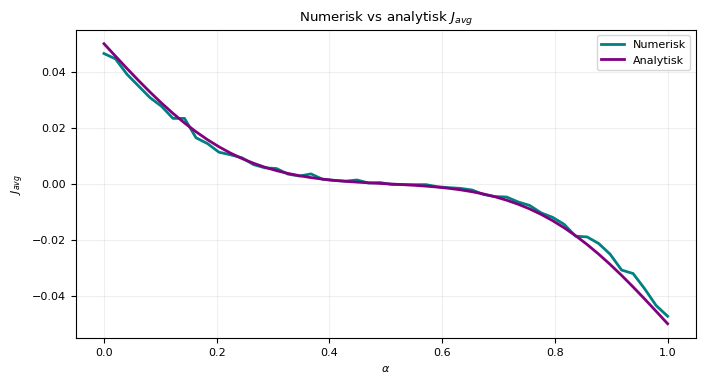

In [80]:
J_avg_alpha(alpha_vals, oppgave= 'c')

##### Kommentar til koden:

Plottet viser at den numeriske og analytiske løsningen av $J_{avg}$ er svært like. For  $\alpha < 0.5$ gir det positv strømning, mens høye verdier, $\alpha > 0.5$, gir negativ strømning. Både den analytiske og den numeriske løsningen gir $J_{avg} = 0$ ved $\alpha \approx 0.5$. Her er sagtannspotensialet symmetrisk og sannsynligheten or å bevege seg mot høyre eller venstre blir dermed lik og kansellerer hverandre. En netto strøm oppstår altså kun ved asymmetrisk potensial. Plottingen av $J_{avg}$ som funskjon av $\alpha$ viser tydelig at retningen på strømmen kontrolleres av forskyvningen gitt av $\alpha$. Avviket mellom den numeriske og analytisk løsningen øker når $\alpha$ går mot 0 og 1, men samsvarer godt rundt $\alpha \approx 0.5$. Forskjellen mellom den numeriske og analytiske løsningen kan visualiseres ved å plotte absolutt differanse.


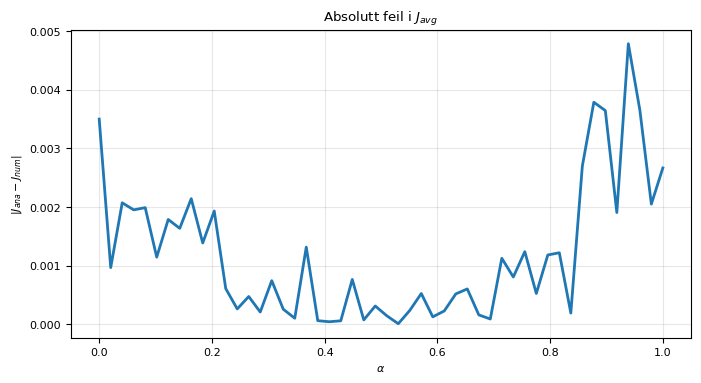

In [81]:
diff = J_analytical - J_num

abs_diff = np.abs(diff)

plt.figure()
plt.plot(alpha_vals, abs_diff)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$| J_{ana} - J_{num}| $")
plt.title("Absolutt feil i $J_{avg}$")
plt.grid(alpha=0.3)
plt.show()

Plottet viser som tidligere nevnt at løsningene samsvarer best rundt $\alpha \approx 0.5$, og  at avvikene øker når $\alpha$ går mot 0 og 1. I start og sluttverdiene for $\alpha$ blir sagtanpotensialet svært asymmetrisk. Fysisk vil det tilsi at partiklene nesten alltid vil falle mot en bestemt retning. Dermed vil strømmen domineres av noen få hopp. Dette kan bidra til små numeriske forskjeller som gir store avvik for $J_{avg}$. 

Dersom verdiene i eksponentialfunksjonen "np.exp()" blir for store, resulterer det i en "RuntimeWarning" og overflow. Det vil si at verdiene er for store for å passe valgt datatype. Standarden til python for float er 64-bit [NumPy – Basic data types](https://numpy.org/doc/stable/user/basics.types.html). En enkel løsning er dermed å endre til en datatype som klarer å håndtere større tall. Det finnes innebygde funksjoner i numpy som kan konvertere til eksempelvis 128-bit. Ved konvertering av datatype vil eksponentialfunksjonen klare å ta inn større verdier uten å få feilmeldinger. Eksponentialfunksjonen for $p_{plus}$ og $p_{minus}$ tar inn potensialert i tillegg til $\beta k$. Siden $\beta k = 1000 $ allerede er en kjent verdi vil det være enkelt å bytte datatype på denne variabelen. Testing av koden med endret dataype gir nå ingen feilmeldinger.

#### Oppgave 3d)

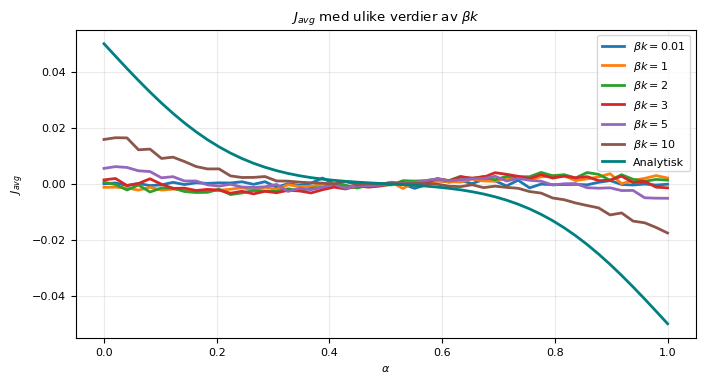

In [ ]:

Beta_k_vals = [0.01, 1, 2, 3, 5, 10]

plt.figure()

for Beta_k in Beta_k_vals:
    J_avg_alpha(alpha_vals, T_p=T_p, N_x=N_x, Beta_k=Beta_k, N_p=N_p, oppgave='d')

#hvis du også vil ha analytisk kurve:
plt.plot(alpha_vals, J_analytical, label="Analytisk", color="teal")

plt.grid(alpha=0.25)
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$J_{avg}$")
plt.title(r"$J_{avg}$ med ulike verdier av $\beta k$")
plt.legend(loc="upper right")
plt.show()

##### Kommentar til kode:

Plottet ovenfor viser hvordan $J_{avg}$ fra oppgave 3c varierer med ulike verdier insatt for $\beta k$. Resultatet viser at $J_{avg}$ ikke bare avhenger av $\alpha$, men også av temperatur, $\beta = (k_b T)^{-1}$. Høye temperaturer resulterer i lave verdier for $\beta k$ som gir $e ^{- \beta V(x)} \approx 1$. Dermed blir strømmen uavhengig av potensialet som resulterer i at $J_{avg} \approx 0$ for lave verdier av $\beta k$ som observert i plottet. Med økende $\beta k$ får potensialt en innvirkning på bevgelsen, og netto strøm vil oppstå. For $\beta k \in (5, 10)$ følger $J_{avg}$  samme trend som for den analytiske løsningen. Positiv strøm for $\alpha < 0.5$, og negativ for $\alpha > 0.5$. For $\alpha = 0$ er systemet symmetrisk, og det vil ikke oppstå netto strøm uavhengig av verdien til $\beta k$.

Den analytiske kurven viser hvordan systemet ideelt sett vil oppføre seg, og hvor potensialet styrer bevegeslen. Denne antakelsen vil brytes for små verdier av $\beta k$ som observert i plottet. Lave verdier av $\beta k$ resulterer i tilfeldige bevegelser fra temperaturen, altså støy. Dermed vil den numeriske modellen samsvare dårlig med den analytiske ettersom den analytsike løsningen legger til grunn at bevegelsen kun påvirkes av sagtann-potensialet. Økende $\beta k$ gir redusert støy og en tydeligere retningsbasert strøm. Samlet sett vsier dette at $\beta k$ har en innvirkning på balansen mellom støy og sterkt potensialet påvirker bevegelsen. 

#### Oppgave 3e)

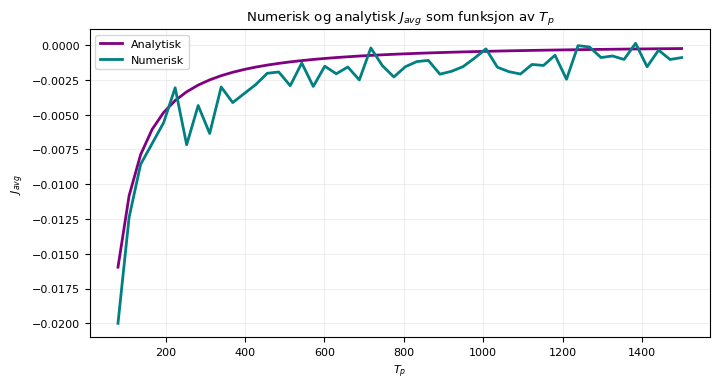

In [95]:
alpha = 0.8
N_x = 10
P = 2 * N_x
N_p = 40 * N_x
Beta_k = 1000

T_p_vals = np.linspace(80, 1500, 50).astype(int)

def J_anal(T_p, alpha=0.8, N_x=10):
    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p)) * (math.erfc(a) - math.erfc(b))

# initialtilstand som i 3b
V1_tmp = build_V1(alpha, N_x)
min1 = np.argmin(V1_tmp[:N_x])
min2 = N_x + np.argmin(V1_tmp[N_x:])
x0 = np.array([min1] * (N_p // 2) + [min2] * (N_p // 2), dtype=int)

#numerisk
J_num = np.zeros(len(T_p_vals))
for i, T_p in enumerate(T_p_vals):
    J_avg, _, _ = simulate_ratchet(alpha=alpha,T_p=T_p, N_x=N_x, N_p=N_p,Beta_k=Beta_k, n_cycles=1,frø=i, x_init=x0,a=False,plot=False)
    J_num[i] = J_avg[0]

#analytisk
J_analytical = np.array([J_anal(T_p, alpha=alpha, N_x=N_x) for T_p in T_p_vals])

# plot
plt.plot(T_p_vals, J_analytical, label="Analytisk", color="purple")
plt.plot(T_p_vals, J_num, label="Numerisk", color="teal")
plt.title(r"Numerisk og analytisk $J_{avg}$ som funksjon av $T_p$")
plt.grid(alpha=0.2)
plt.xlabel(r"$T_p$")
plt.ylabel(r"$J_{avg}$")
plt.legend()
plt.show()
 

##### Kommentar til koden:
Plottet ovenfor viser en numerisk og analystisk løsning av $J_{avg}$ som funksjon av perioden $T_p$, med 20 ulike verdier av $T_p \in (80, 1500)$ og $\alpha = 0.8$. $J_{avg}$ er negativ både for den analytiske og numeriske løsningen for alle $T_p$. Dette er forventet ettersom $\alpha = 0.8$, altså er toppen av sagtannen forskjøvet mot høyre som resulterer i en strøm mot venstre. 
Lave verdier av $T_p$ gir størst absoluttverdi for $J_{avg}$. Dette kan forklares av at partiklene ikke rekker å spre seg i det flate potensiale, noe som kan lede til en sterk skjevhet når sagtannpotensialet bli påslått, og dermed en sterk strøm. Til tross for et større avvik for små verdier av $T_p$, følger begge kurvene samme trend. Ettersom verdien for $T_p$ øker, avtar $J_{avg}$ gradvis mot 0 for både den analytsike og numeriske løsningen. Slik som observert i oppgave 3b kan en økt periode lede til at partiklene rekker å spre seg nesten symmetrisk rundt minimum. Dermed vil bidragene kansellere ut hverandre og gir mindre netto forskyvning.

Den numeriske løsningen følger den analytiske i varierende grad. Dette kan undersøkes ved å se på absoluttverdien av differansen mellom kurvene.

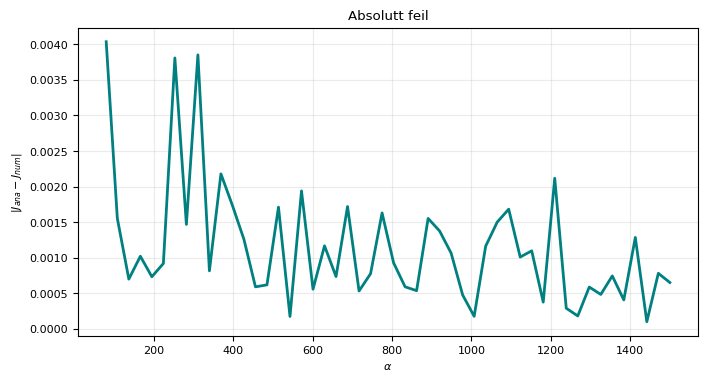

In [96]:
diff = J_analytical - J_num

abs_diff = np.abs(diff)

plt.figure()
plt.plot(T_p_vals, abs_diff, color = "teal")
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$ | J_{ana} - J_{num} | $")
plt.title("Absolutt feil")
plt.grid(alpha=0.25)
plt.show()

Som observert på det første plottet er det et merkbart avvik i $T_p = 0$. Partiklene får veldig lite tid på å spre seg, som gir tildelige bevegelser, og dermed et resultat som er tynget av støy for den numeriske løsningen. For den analutiske løsningen er det antatt at partiklene rekker å spre seg jevnt før sagtann-potensialet blir påslått som gir en kontinuerlig og fin kurve. Dette er en dårlig antakelse for små verdier av $T_p$, og resulterer da i et stort avvik mellom den numeriske og analytiske løsningen. Med økende $T_p$ får partiklene mer tid til å bevege seg, og støyen vil bli mindre dominerende, noe som gir mindre avvik mellom de to kurvene. 

#### Oppgave 3f)

Den analytiske løsningen fungerer ikke optimalt i alle tilfeller grunnet implisitte antakelser.
I oppgave 3d undersøkes strømmen $J_{avg}$ for ulike verdier av $\beta k \in (0.01, 1, 2, 3, 5, 10)$. Den analytiske løsningen legger til grunn at potensialet er sterkt nok til å styre bevegelsen, med en implisitt antakelse om at potensialet påvirker partikkelbevegelsen betraktelig når det er påslått. Som observert i plottet for 3d viser det seg at denne antakelsen ikke holdt for mindre verdier av $\beta k$. Ettersom $\beta = (k_b T)^{-1}$, gir svært høye temperaturer en $\beta \approx 0$. Dermed vil $e ^{- \beta V(x)}  \approx 0$, og potensialet har dermed ingen innvirkning på strømmen. Dette bryter med antakelsene til den analytiske løsningen, og den vil dermed ikke holde for små verdier av $\beta k$.

Videre viste det seg at antakelsene for den analytiske løsningen også stemte dårlig for deler av oppgave 3e. For små verdier av perioden $T_p$ var avviket mellom den numeriske og analytiske løsningen markant. For den analytiske løsningen antas det at partiklene rekker å spre seg jevnt før sagtann-potensialet blir påslått. Dette resulterer i en glatt kurve, og er en urealistisk antakelse for små perioder. I realiteten får partiklene kort tid på å spre seg, noe som gir ujevn partikkelfordeling og et resultat som er svært påvirket av starttilstanden. 

Den analytiske løsningen funegrer altså best når eprioden $T_p$ er tilstrekkelig 

### Oppgave 4

#### Oppgave 4a)

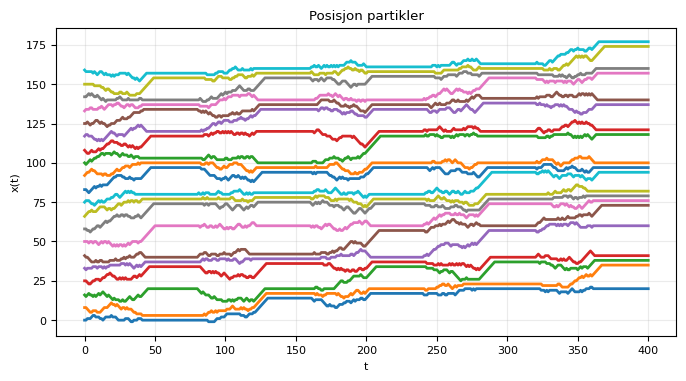

In [ ]:
alpha = 0.2
N_x = 20
P = 2 * N_x
L = 4 * P
beta_k = 1000
T_p = 40
N_c = 5
t_steps = 2 * N_c * T_p

n_par = 20
b = 3

def build_V1(alpha, N_x):
    limit = int(alpha * N_x)
    n = np.arange(N_x)
    V = np.zeros(N_x, dtype=float)
    left = (n <= limit)
    right = (n > limit)
    V[left] = n[left] / max(limit, 1)
    V[right] = (N_x - n[right]) / max((N_x - limit), 1)
    return np.concatenate([V, V])

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, 4)
V2 = np.zeros(L)

x0 = np.linspace(0, L-1, n_par, dtype=int)

def probs_single(V, x0, beta_k):
    V_l = V[(x0 - 1) % L]
    V_0 = V[x0]
    V_r = V[(x0 + 1) % L]
    p_plus = 1 / (1 + np.exp(-beta_k*(V_l - V_r)) + np.exp(-beta_k*(V_0 - V_r)))
    p_0 = 1 / (1 + np.exp(-beta_k*(V_r - V_0)) + np.exp(-beta_k*(V_l - V_0)))
    p_minus = 1 / (1 + np.exp(-beta_k*(V_r - V_l)) + np.exp(-beta_k*(V_0 - V_l)))
    return p_plus, p_0, p_minus

def hardcore_flash(x0, t_steps, N_p, T_p):
    x = x0.copy().astype(int)
    traj = np.zeros((t_steps + 1, N_p), dtype=int)
    traj[0] = x

    J_list = []
    
    
    for i in range(t_steps):
        off_part = (i % (2 * T_p)) < T_p
        if off_part:
            V = V2
        else:
            V = V1
        
        occupied = set()
        for xi in x:
            for k in range(b):
                occupied.add((xi + k) % L)
            
        order = np.random.permutation(len(x))

        n_m = 0
        n_p = 0

        for j in order:
            if off_part:
                p_plus, p_0, p_minus = 1/3, 1/3, 1/3
            else:
                p_plus, p_0, p_minus = probs_single(V, x[j], beta_k)
                
            r = np.random.rand()

            if r <= p_minus:
                new_pos = (x[j] - 1) % L
            elif r > (1 - p_plus):
                new_pos = (x[j] + 1) % L
            else:
                continue

            if new_pos == (x[j] + 1) % L:
                new_site = (x[j] + b) % L
                if new_site not in occupied:
                    occupied.discard(x[j])
                    occupied.add(new_site)
                    x[j] = new_pos
                    n_p += 1

            elif new_pos == (x[j] - 1) % L:
                new_site = (x[j] - 1) % L
                if new_site not in occupied:
                    occupied.discard((x[j] + b - 1) % L)
                    occupied.add(new_site)
                    x[j] = new_pos
                    n_m += 1
                    
        traj[i+1] = x.copy()
        J_list.append((n_p - n_m) / N_p)

        
    return traj, np.mean(J_list)

traj, J = hardcore_flash(x0, t_steps, n_par, T_p)

traj_unwrap = traj.copy().astype(int)
for j in range(n_par):
    for t in range(1, t_steps + 1):
        dx = traj[t, j] - traj[t-1, j]
        if dx > L // 2:
            traj_unwrap[t:, j] -= L
        elif dx < -L // 2:
            traj_unwrap[t:, j] += L

for j in range(n_par):
    plt.plot(np.arange(t_steps + 1), traj_unwrap[:, j])
plt.title("Posisjon partikler")
plt.grid(alpha=0.25)
plt.xlabel("t")
plt.ylabel("x(t)")
plt.show()


##### Kommentar til kode:

Figuren som plottes viser posisjonen $x(t)$ til $n$ partikler med bredde $b$ som funksjon av tiden $t$ for alle partiklene i systemet. Hver kurve representerer banen til en partikkel gjennom simuleringen. Kurvene består av bevegelsene til partiklene i potensialet, der de beveger seg i små hopp langs gitteret. I perioder der en partikkel ikke kan flytte seg, fordi plassen foran er blokkert av en annen partikkel, vil kurven være flat. Når flere partikler beveger seg samtidig kan vi se grupper av kurver som følger hverandre tett, noe som illustrerer hvordan *hard-core*-interaksjonen fører til en mer sammenhengende dynamikk. Vi valgte antall partikler $n$ lik tjue, med en bredde $b$ lik tre, som påvirker hvor mye kø som vil dannes og hvor begrenset bevegelsen til partiklene blir. Figuren gir derfor et visuelt bilde av hvordan både ratchet-potensialet og partikkelinteraksjonene påvirker bevegelsen i systemet.

Simuleringen viser hvordan partikler beveger seg i et *"flashing ratchet"*-system, der potensialet veksler mellom et flatt potensial og et asymmetrisk ratchet-potensial. Når potensialet er flatt, er det ingen foretrukket retning for bevegelsen, da alle bevegelser har lik sannsynlighet. Når ratchet-potensialet slås på, blir bevegelsen påvirket av potensialets asymmetri, altså at potensialet ikke er symmetrisk rundt minimumspunktene. I dette tilfellet bestemmes asymmetrien av parameteren (\alpha), som styrer hvor bratt potensialet stiger på den ene siden av en potensialbrønn sammenlignet med den andre siden, slik som ble nevnt i oppgave 3a. Dersom den ene siden av potensialet er brattere enn den andre, blir det lettere for partiklene å bevege seg i en retning over den andre. Når systemet veksler mellom flatt og asymmetrisk potensial kan denne forskjellen i bevegelsesmulighet føre til en liten netto transport i en av retningene. Dette kommer frem i figuren ved at noen av partiklene er forskøvet mot venstre, mens noen er ved samme posisjon som da de startet.

Partiklene i modellen har også *"hard-core repulsion"*, som betyr at de ikke kan overlappe eller passere hverandre. Hver partikkel opptar derfor flere gitterpunkter, avhengig av bredden $b$, og en partikkel kan bare flytte seg dersom plassene foran er ledige. Dette gjør at rekkefølgen av partiklene langs gitteret bevares gjennom hele simuleringen. Konsekvensen er at bevegelsen til en partikkel ofte kan bli blokkert av en nabopartikkel. Slike blokkeringer skaper sammenhengende bevegelser i systemet, hvor partiklene ikke lenger beveger seg helt uavhengig, men i stedet påvirker hverandres dynamikk som vi ser i plottet over. Transporten i systemet bestemmes derfor både av ratchet-potensialets form og av hvor tett partiklene ligger.


#### Oppgave 4b)

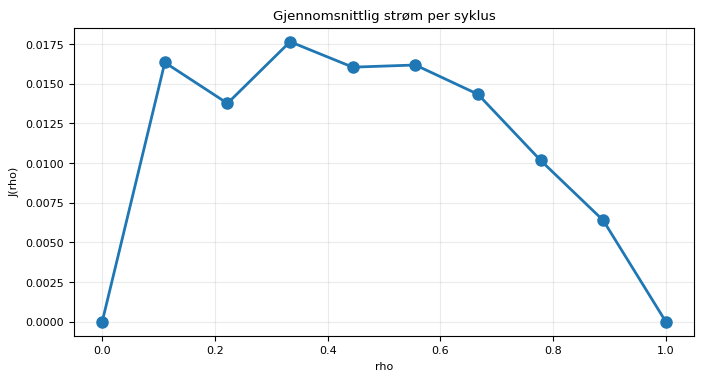

In [ ]:
N_s = 10
beta_k = 1000
N_x = 100
T_p = 300
alpha = 0.2
b = 20
N_c = 100
t_steps = 2 * N_c * T_p

L = N_x * N_s 

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, N_s) 
V2 = np.zeros(L)

p_vals = np.linspace(0,1,10) 
J_vals = []

for p in p_vals:
    if p == 0:
        J_vals.append(0)
        continue

    N_p = int(np.round((p * N_s * N_x) / b))
    N_p = max(N_p, 1)

    x0 = np.linspace(0, L-1, N_p, dtype = int)

    traj, J = hardcore_flash(x0, t_steps, N_p, T_p)
    J_vals.append(J)

J_vals = np.array(J_vals)

plt.plot(p_vals, J_vals, '-o')
plt.title("Gjennomsnittlig strøm per syklus")
plt.grid(alpha=0.25)
plt.xlabel("rho")
plt.ylabel("J(rho)")
plt.show()


#### Kommentar til kode:

Figuren som plottes viser den gjennomsnittlige strømmen som funksjon av partikkeltettheten i systemet. Hvert punkt i plottet representerer resultatet av en simulering der tettheten av partikler endres, mens de øvrige parameterne holdes konstante. Strømmen beskriver hvor mye netto transport som oppstår i systemet når partiklene beveger seg i et *flashing ratchet*-potensial.

Ved lav tetthet er det relativt få partikler i systemet, og de kan derfor bevege seg nesten uavhengig av hverandre. Blokkering mellom partikler forekommer sjelden, og de fleste forsøk på å hoppe til et nabogitterpunkt lykkes. Når tettheten øker, blir det flere partikler som bidrar til transporten gjennom systemet, og den totale strømmen øker derfor i dette området. I dette regimet domineres dynamikken fortsatt av ratchet-mekanismen, der vekselvirkningen mellom diffusjon i den flate fasen og asymmetrien i potensialet gir en netto transport i én retning.

Når tettheten blir større, begynner *hard-core*-interaksjonene mellom partiklene å spille en viktigere rolle. Siden partiklene ikke kan overlappe eller passere hverandre, vil en partikkel ofte bli blokkert dersom plassen foran er opptatt. Slike blokkeringer fører til at bevegelsen til partiklene blir mer sammenhengende og begrenset. Antallet ledige gitterpunkter som partiklene kan hoppe til blir mindre, og mobiliteten i systemet reduseres.

Dette fører til at strømmen etter hvert når et maksimum for en moderat tetthet, før den deretter avtar når systemet blir stadig tettere pakket. Ved høy tetthet er det få ledige plasser igjen på gitteret, og partiklene har derfor begrensede muligheter til å flytte seg. Transporten i systemet blir da sterkt hemmet, og den gjennomsnittlige strømmen går ned. Figuren illustrerer dermed hvordan konkurransen mellom ratchet-mekanismen og blokkering på grunn av *hard-core*-interaksjoner bestemmer transporten i systemet.


#### Oppgave 4c)

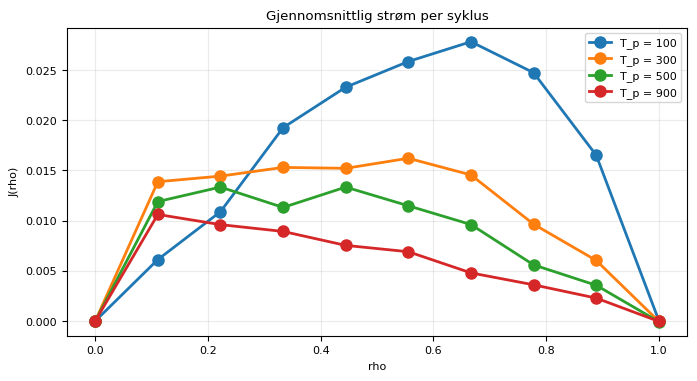

In [ ]:
N_s = 10
beta_k = 1000
N_x = 100
alpha = 0.2
b = 20

L = N_x * N_s 

V_one = build_V1(alpha, N_x)
V1 = np.tile(V_one, N_s) 
V2 = np.zeros(L)

p_vals = np.linspace(0,1,10) 

T_p_vals = [100,300,500,900]

for T_p in T_p_vals:

    N_c = int(np.round(30000 / T_p))
    t_steps = 2 * N_c * T_p

    J_vals = []
    for p in p_vals:
        if p == 0:
            J_vals.append(0)
            continue

        N_p = int(np.round((p * N_s * N_x) / b))
        N_p = max(N_p, 1)

        x0 = np.linspace(0, L-1, N_p, dtype = int)

        traj, J = hardcore_flash(x0, t_steps, N_p, T_p) 
        J_vals.append(J)

    J_vals = np.array(J_vals)

    plt.plot(p_vals, J_vals, '-o', label=f"T_p = {T_p}")
plt.legend()
plt.title("Gjennomsnittlig strøm per syklus")
plt.grid(alpha=0.25)
plt.xlabel("rho")
plt.ylabel("J(rho)")
plt.show()




#### Kommentar til koden:

Figuren som plottes viser den gjennomsnittlige strømmen $J(\rho)$  som funksjon av partikkeltettheten $\rho$ for ulike verdier av perioden $T_p$ i flashing ratchet-modellen. Hver kurve representerer en simulering der tiden potensialet er av eller på varierer, mens den totale simuleringstiden holdes konstant. Ved å endre $T_p$ undersøker vi hvordan hastigheten på vekslingen mellom det flate potensialet og ratchet-potensialet påvirker transporten i systemet.

Når $T_p$ er liten, veksler systemet raskt mellom de to potensialene. I dette tilfellet får partiklene kortere tid i hver fase av potensialet, men systemet reorganiserer seg også oftere. Dette kan føre til at partiklene i mindre grad blir stående fast i tette strukturer, og blokkering mellom partikler reduseres. Resultatet er at strømmen kan bli relativt stor for moderate tettheter, noe vi også ser for de minste verdiene av $T_p$ i figuren.

Når $T_p$ øker, tilbringer systemet lengre tid i hvert potensial. Partiklene får da mer tid til å diffundere i den flate fasen, men de får også mer tid til å samle seg og blokkere hverandre når tettheten er høyere. Dette fører til at kø-lignende strukturer lettere oppstår i systemet, noe som reduserer mobiliteten og dermed også den gjennomsnittlige strømmen. Derfor ser vi at kurvene for større $T_p$ generelt ligger lavere enn kurvene for mindre $T_p$.

Som i oppgave 4b ser vi også at strømmen først øker med tetthet før den avtar igjen. Ved lav tetthet er det få partikler i systemet og blokkering skjer sjelden, slik at flere partikler bidrar til transporten når tettheten øker. For høy tetthet blir derimot systemet mer tettpakket, og *hard-core*-interaksjonene gjør at partiklene i større grad blokkerer hverandre. Når tettheten nærmer seg én finnes det nesten ingen ledige gitterplasser igjen, og alle kurvene går derfor mot null fordi partiklene ikke lenger kan bevege seg fritt i systemet.


#### Oppgave 4d)

For å kontrollere at modellen vår gir rimelige resultater kan vi sammenligne med tidligere publisert forskning. En relevant artikkel for dette prosjektet er *“Stochastic transport of interacting particles in periodically driven ratchets”* av Savel’ev, Marchesoni og Nori (2004). Denne artikkelen diskuterer transport av partikler som beveger seg i et asymmetrisk periodisk ratchet-potensial, der systemet holdes ute av likevekt ved for eksempel temperatur-oscillasjoner eller en tidsavhengig kraft. Partiklene reagerer gjennom repulsive interaksjoner, som gir en hard-core-lignende eksklusjon, på samme måte som i modellen vi har brukt i dette prosjektet.

Et av resultatene fra artikkelen er vist i figuren under, hvor den gjennomsnittlige partikkelhastigheten eller strømmen plottes som funksjon av partikkeltettheten $n$. Figuren viser at nettohastigheten $V_{dc}=J/n$ avtar raskt når tettheten av repellerende partikler øker. Dette forklares ved at partiklene i større grad blokkerer for hverandre når tettheten blir større. Dermed blir det effektive potensialet flatere, noe som reduserer asymmetrien i ratchet-potensialet og svekker ratchet-effekten. Som beskrevet i artikkelen: *“the net velocity $V_{dc}=J/n$ typically decays rapidly with increasing density of the repelling particles (…) the effective potential flattens out and this suppresses the ratchet asymmetry.”*. Dette stemmer godt overens med resultatene vi fant i oppgave 4b, der strømmen også avtar når tettheten blir stor.

<img src="Oppgave4d.png" width="500">

Resultatet skiller seg fra tilfellet der det ikke tas hensyn til at kun en partikkel kan ha en posisjon, og de ikke vil blokkere hverandre. Dersom partiklene ikke påvirker hverandre, kan hver partikkel bevege seg uavhengig i potensialet, og strømmen per partikkel vil derfor ikke reduseres på samme måte når tettheten øker. Når repulsive interaksjoner tas med i modellen oppstår derimot blokkering og sammenhengende bevegelser mellom partiklene, noe som gjør transporten mindre effektiv ved høyere tetthet. Sammenligningen med denne artikkelen viser derfor at simuleringen vår gir resultater som er konsistente med tidligere forskning på ratchet-systemer med interagerende partikler.

### Referanseliste

Savel'ev, S., Marchesoni, F., & Nori, F. (2004). 
*Stochastic transport of interacting particles in periodically driven ratchets*. 
Physical Review E, 70, 061107. https://doi.org/10.1103/PhysRevE.70.061107